# 05. Explicabilidad de la CNN con Grad-CAM (T67)

¿Dónde mira la CNN (`lr1e-2_b32_frozen`)? ¿Mira el sabotaje (la tapa, el desenfoque, el cambio de escena) o el contexto (luz, cielo, vegetación)? Y, sobre todo: ¿qué explica la caída de F1 de 0,97 en test (ubicación 1) a 0,58 en la cámara no vista (ubicación 2)?

Grad-CAM pondera los 7×7 mapas de la última convolución de MobileNetV2 por el gradiente medio del puntaje de la clase (antes del softmax). Es un mapa **grueso**: indica zonas, no píxeles. Código: `src/explain_cnn.py`; se genera con `python -m src.explain_cnn`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGURES = ROOT / 'results' / 'figuras'
RUN = ROOT / 'results' / 'cnn' / 'lr1e-2_b32_frozen'
stats = pd.read_csv(RUN / 'gradcam_resumen.csv')

## 1. Ejemplos en test (ubicación 1)

4 imágenes al azar de cada clase (semilla fija). En rojo, el título de los errores.

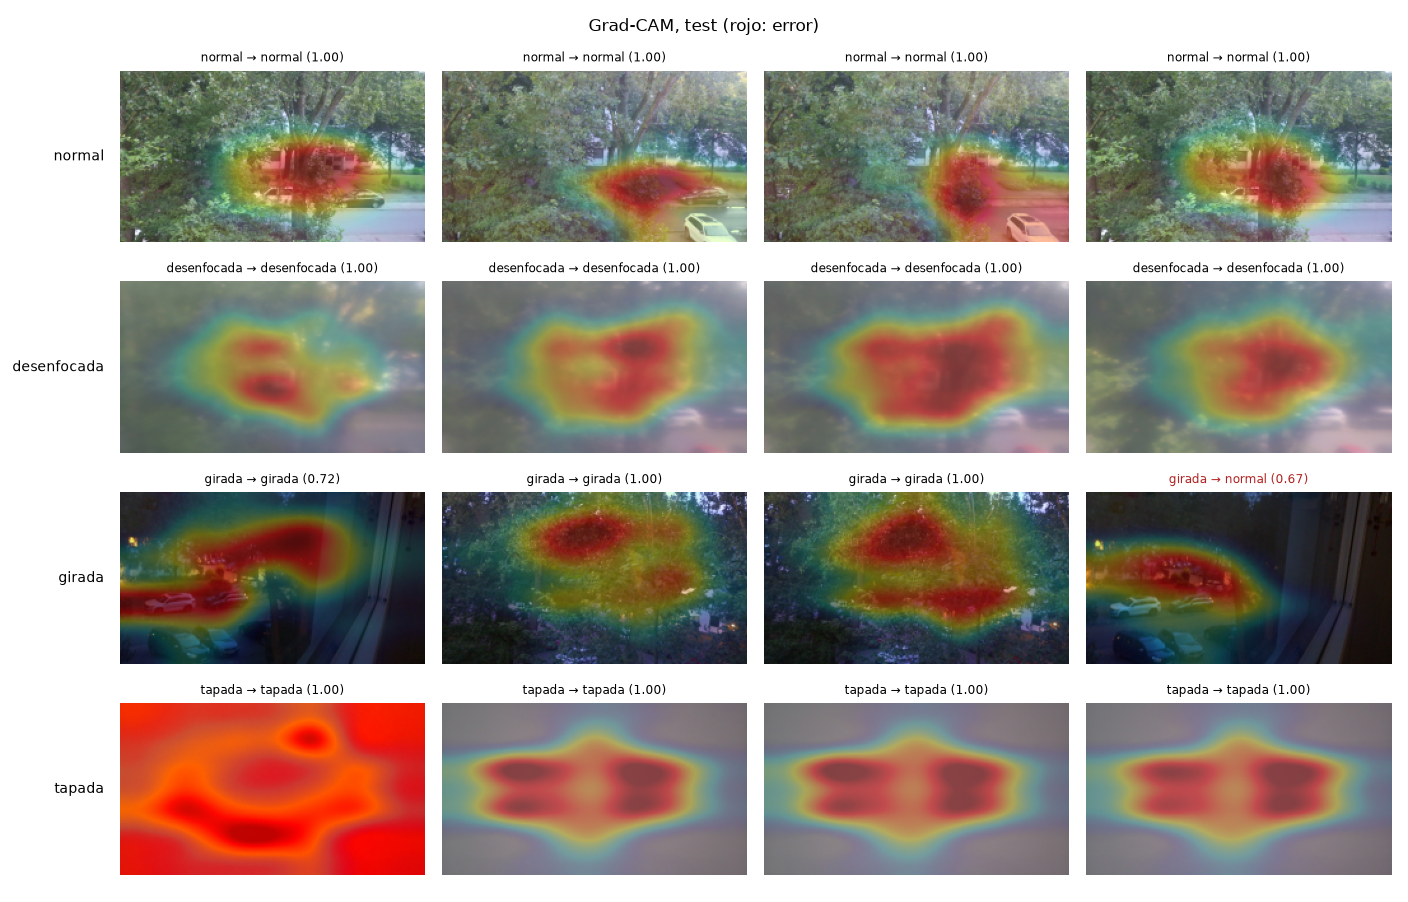

In [2]:
display(Image(filename=str(FIGURES / 'gradcam_test.png')))

## 2. Ejemplos en la cámara no vista (ubicación 2)

No tiene tapadas (las de la ubicación 2 eran copias de la ubicación 1, ver `docs/datos.md`).

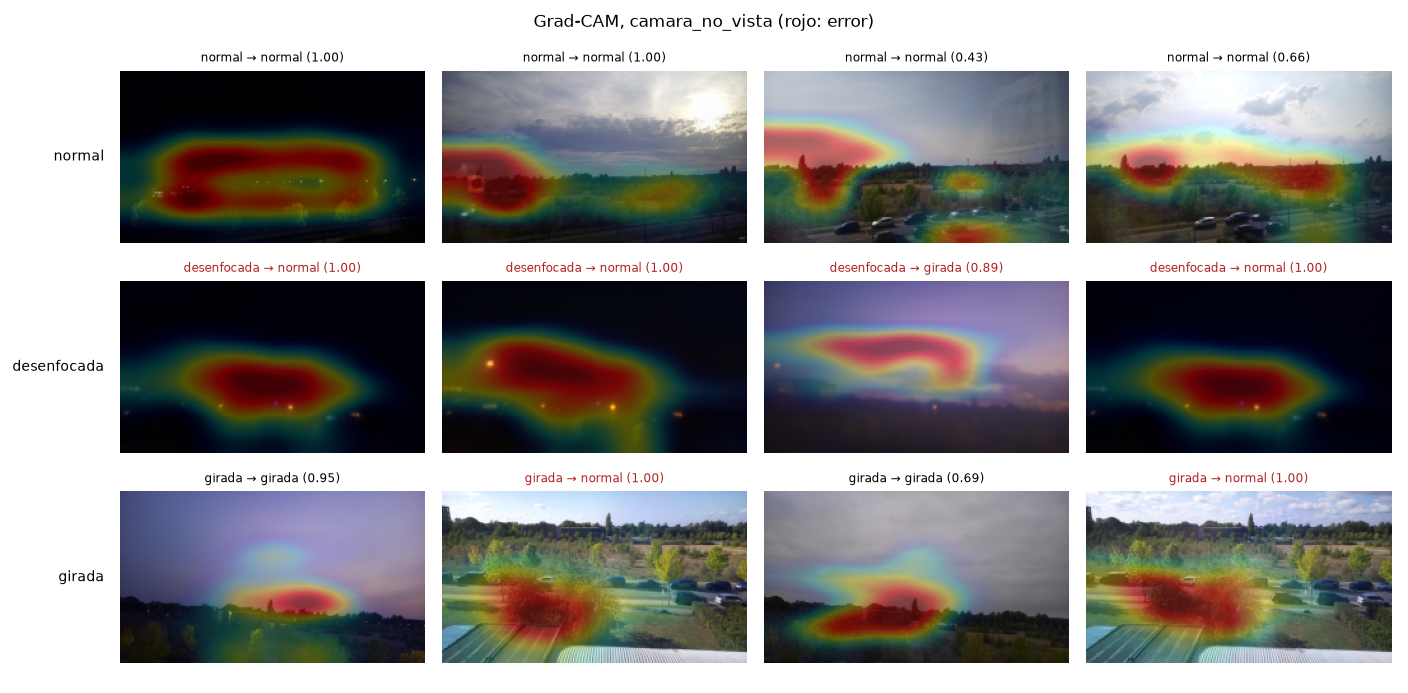

In [3]:
display(Image(filename=str(FIGURES / 'gradcam_camara_no_vista.png')))

## 3. Dónde se concentra la atención

Para **todas** las imágenes de cada conjunto (327 de test y 1163 de la cámara no vista): centro de la atención (0 = izquierda o arriba, 1 = derecha o abajo), parte de la atención en cada tercio vertical de la imagen y concentración (0 = uniforme, 1 = una sola celda).

In [4]:
cols = ['conjunto', 'label', 'acierto', 'n', 'centro_y', 'tercio_superior', 'tercio_medio', 'tercio_inferior', 'concentracion', 'prob']
stats[cols]

,conjunto,label,acierto,n,centro_y,tercio_superior,tercio_medio,tercio_inferior,concentracion,prob
0,camara_no_vista,desenfocada,False,171,0.573,0.053,0.725,0.223,0.192,0.864
1,camara_no_vista,desenfocada,True,80,0.568,0.102,0.649,0.249,0.265,0.805
2,camara_no_vista,girada,False,102,0.578,0.095,0.619,0.286,0.134,0.901
3,camara_no_vista,girada,True,65,0.614,0.051,0.611,0.338,0.187,0.774
4,camara_no_vista,normal,False,31,0.474,0.230,0.630,0.140,0.186,0.690
5,camara_no_vista,normal,True,714,0.636,0.012,0.642,0.346,0.146,0.949
6,test,desenfocada,True,68,0.492,0.177,0.673,0.150,0.106,1.000
7,test,girada,False,2,0.532,0.102,0.699,0.199,0.166,0.825
8,test,girada,True,7,0.433,0.299,0.572,0.129,0.060,0.796
9,test,normal,True,182,0.593,0.068,0.647,0.285,0.140,0.999


In [5]:
print('Tercio superior (donde suele estar el cielo):', stats['tercio_superior'].min().round(2), 'a', stats['tercio_superior'].max().round(2))
print('Tercio medio:', stats['tercio_medio'].min().round(2), 'a', stats['tercio_medio'].max().round(2))
print('Probabilidad media de la clase predicha en los errores de la cámara no vista:')
stats[(stats['conjunto'] == 'camara_no_vista') & (~stats['acierto'])][['label', 'n', 'prob']]

Tercio superior (donde suele estar el cielo): 0.01 a 0.3
Tercio medio: 0.57 a 0.72
Probabilidad media de la clase predicha en los errores de la cámara no vista:


,label,n,prob
0,desenfocada,171,0.864
2,girada,102,0.901
4,normal,31,0.690


## 4. Conclusión

1. **La CNN mira la zona central de la imagen, sin importar la clase.** El tercio medio concentra entre 0,57 y 0,73 de la atención en todas las clases y en las dos cámaras; el tercio superior (donde suele estar el cielo) entre 0,01 y 0,30. La hipótesis de que la CNN se apoya en el **cielo** no se sostiene. La atención es difusa (concentración baja) y casi no cambia entre clases, así que no se ve una zona propia del sabotaje.
2. **En test la atención sigue el contenido de la escena o la textura global, no una señal local de sabotaje.** En las normales cae sobre la carretera y los autos; en las desenfocadas, sobre una mancha central grande; en las tapadas, sobre el mismo dibujo simétrico en el centro, casi idéntico en imágenes distintas: la cubierta es casi uniforme y ese patrón probablemente viene de la estructura de la red (bordes del campo receptivo) más que de algo que "vea". Es una hipótesis, no está probada.
3. **En la cámara no vista los errores son seguros, no dudosos.** Las desenfocadas mal clasificadas (como normal o girada) se predicen con probabilidad media de 0,86 y las giradas mal clasificadas, de 0,90. Se equivoca con confianza, no por indecisión: son un cambio de dominio (otra escena, otra luz, otro cielo), no incertidumbre.
4. **La oscuridad por sí sola no lo explica.** Muchas de esas imágenes son nocturnas, pero la auditoría (`docs/auditoria.md`, sección 5) muestra que oscurecer las imágenes de la ubicación 1 casi no degrada la CNN (F1 0,993 con brillo × 0,3). Lo que cambia entre cámaras es el contenido y la textura de la escena.

**Para la defensa:** Grad-CAM no permite afirmar que la CNN "mira el sabotaje". Muestra que mira el centro de la escena y que, con otra cámara, ese contenido ya no le sirve. El clásico generaliza mejor porque decide con comparaciones contra referencias de la **misma** cámara (docs/clasico.md).

**Límites:** el mapa es grueso (7×7), explica una sola corrida y una sola semilla, y se calcula solo sobre la clase predicha. No se probó con LIME ni SHAP.